In [12]:
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np
import torch
import os

In [ ]:
print("Torch :", torch.__version__)
print("CUDA :", torch.version.cuda)
print("CUDA Available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

Torch : 2.11.0+cu128
CUDA : 12.8
CUDA Available : True
NVIDIA GeForce RTX 3060


In [8]:
DATA_DIR = Path("../data")

TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

print(TRAIN_DIR)
print(TEST_DIR)

..\data\train
..\data\test


In [13]:
print(os.listdir(TRAIN_DIR))

['0_Recyclable', '1_Electronic', '2_Organic']


In [14]:
class_counts = {}

for cls in os.listdir(TRAIN_DIR):
    cls_path = TRAIN_DIR / cls
    
    if cls_path.is_dir():
        class_counts[cls] = len(os.listdir(cls_path))

class_counts

{'0_Recyclable': 9466, '1_Electronic': 3930, '2_Organic': 11457}

In [24]:
data = []

for cls in sorted(TRAIN_DIR.iterdir()):
    if not cls.is_dir():
        continue

    for img_path in cls.glob("*"):
        try:
            with Image.open(img_path) as img:
                w, h = img.size

                data.append({
                    "filename": img_path.name,
                    "class": cls.name,
                    "width": w,
                    "height": h,
                    "aspect_ratio": round(w / h, 3),
                    "mode": img.mode,
                    "file_size_kb": img_path.stat().st_size / 1024
                })

        except Exception:
            print("Error:", img_path)

df = pd.DataFrame(data)

df.head()

,filename,class,width,height,aspect_ratio,mode,file_size_kb
0,R_1.jpg,0_Recyclable,314,160,1.962,RGB,5.182617
1,R_10.jpg,0_Recyclable,300,150,2.000,RGB,6.011719
2,R_100.jpg,0_Recyclable,269,187,1.439,RGB,18.194336
3,R_1000.jpg,0_Recyclable,300,168,1.786,RGB,12.868164
4,R_1001.jpg,0_Recyclable,315,160,1.969,RGB,6.037109


In [16]:
df[["width","height"]].describe()

,width,height
count,24853.00000,24853.000000
mean,303.25176,250.157647
std,416.29251,345.296036
min,33.00000,48.000000
25%,211.00000,170.000000
50%,251.00000,194.000000
75%,275.00000,225.000000
max,8000.00000,6000.000000


In [17]:
df["aspect_ratio"].describe()

count    24853.000000
mean         1.276212
std          0.460997
min          0.162000
25%          1.000000
50%          1.235000
75%          1.503000
max          8.696000
Name: aspect_ratio, dtype: float64

In [18]:
df["mode"].value_counts()

mode
RGB     24593
P         241
RGBA       17
L           2
Name: count, dtype: int64

In [19]:
df["file_size_kb"].describe()

count    24853.000000
mean        45.621869
std        455.662206
min          0.771484
25%          4.708008
50%          7.584961
75%         11.487305
max      19262.674805
Name: file_size_kb, dtype: float64

In [20]:
df.groupby(["width","height"]).size().sort_values(ascending=False).head(20)

width  height
225    225       3875
150    150       2640
275    183       2347
259    194       1550
300    168        833
183    275        465
194    259        338
276    183        324
299    168        308
284    177        208
274    184        189
224    224        177
318    159        168
260    194        155
290    174        149
251    201        125
262    192        115
197    256        109
201    251        109
252    200        107
dtype: int64

In [21]:
print("Width < 100 :", len(df[df.width < 100]))
print("Height < 100:", len(df[df.height < 100]))

print("Aspect ratio > 3 :", len(df[df.aspect_ratio > 3]))
print("Aspect ratio < 0.33 :", len(df[df.aspect_ratio < 0.33]))

Width < 100 : 125
Height < 100: 145
Aspect ratio > 3 : 208
Aspect ratio < 0.33 : 19


In [25]:
df.to_csv("eda_dataset.csv", index=False)

print(df.shape)

(24853, 7)


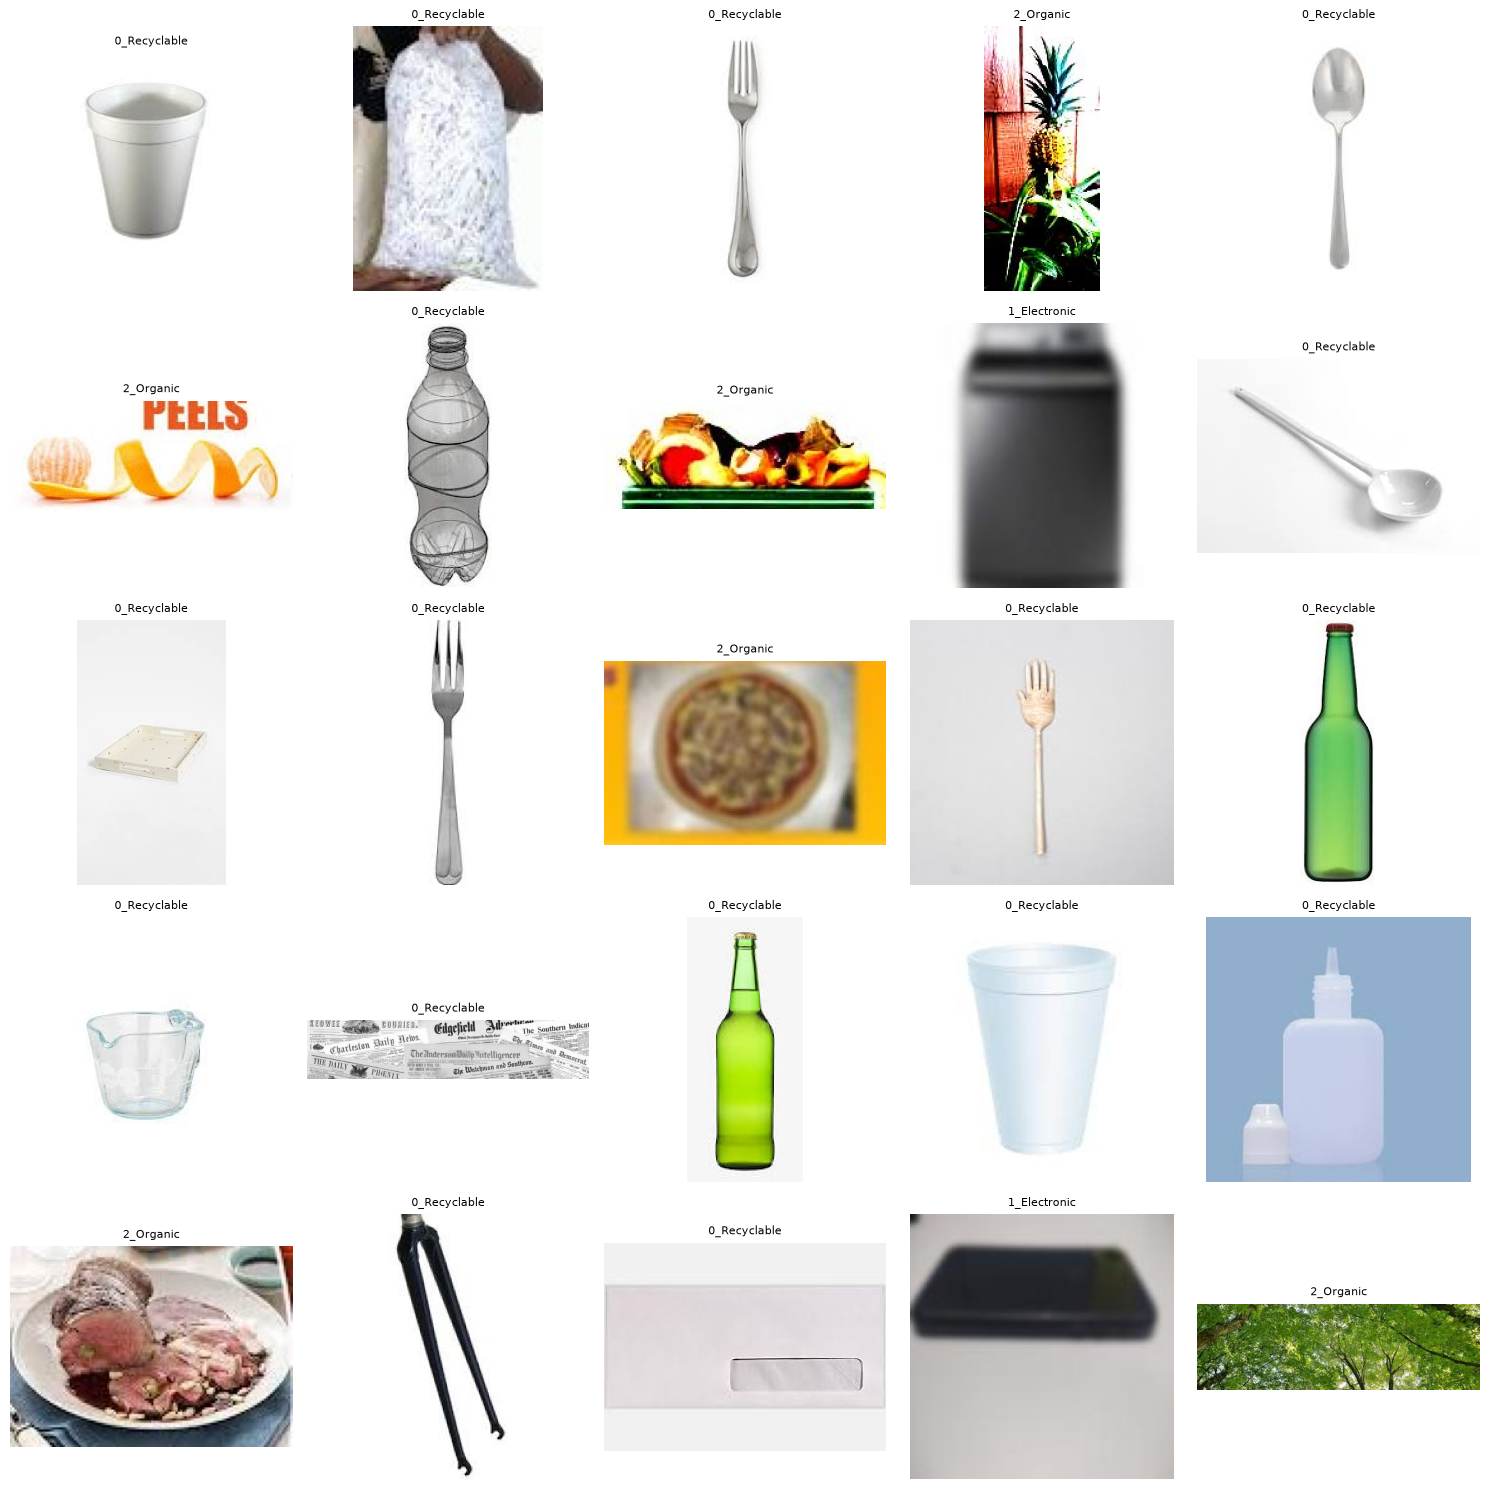

In [30]:
import matplotlib.pyplot as plt
from PIL import Image

sample = small.sample(25, random_state=42)

fig, axes = plt.subplots(5, 5, figsize=(15, 15))

for ax, (_, row) in zip(axes.flatten(), sample.iterrows()):
    img_path = TRAIN_DIR / row["class"] / row["filename"]  # lihat catatan di bawah
    img = Image.open(img_path)

    ax.imshow(img)
    ax.set_title(row["class"], fontsize=8)
    ax.axis("off")

plt.tight_layout()